# Heart Disease Prediction — Model Training & Comparison

Three models, from simple to complex:

1. **Logistic Regression** — linear baseline, fully interpretable
2. **Random Forest** — ensemble of decision trees, captures non-linear patterns
3. **XGBoost** — gradient-boosted trees, usually the strongest on tabular data

Each one is a `Pipeline(preprocessor → classifier)` tuned with a small grid search and **5-fold stratified cross-validation on the training set only**.
The test set stays untouched until the evaluation notebook.

Training code: [`src/train.py`](../src/train.py)

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.preprocess import load_data
from src.train import tune_models, get_model_configs

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", None)

## 1. Data

In [2]:
X_train, X_test, y_train, y_test = load_data()
print("Train:", X_train.shape, " Test (held out):", X_test.shape)

Train: (736, 11)  Test (held out): (184, 11)


## 2. Hyperparameter grids

In [3]:
for name, (clf, grid) in get_model_configs().items():
    n = int(np.prod([len(v) for v in grid.values()]))
    print(f"{name}: {n} combinations x 5 folds = {n * 5} fits")
    for k, v in grid.items():
        print(f"    {k.replace('clf__', '')}: {v}")

Logistic Regression: 4 combinations x 5 folds = 20 fits
    C: [0.01, 0.1, 1, 10]
Random Forest: 18 combinations x 5 folds = 90 fits
    n_estimators: [200, 500]
    max_depth: [None, 5, 10]
    min_samples_leaf: [1, 3, 5]
XGBoost: 24 combinations x 5 folds = 120 fits
    n_estimators: [100, 300]
    max_depth: [2, 3, 4]
    learning_rate: [0.05, 0.1]
    subsample: [0.8, 1.0]


## 3. Train & cross-validate (takes ~2 minutes)

In [4]:
results, best_models = tune_models(X_train, y_train)

Logistic Regression  CV ROC-AUC = 0.883 +/- 0.019


Random Forest        CV ROC-AUC = 0.879 +/- 0.025


XGBoost              CV ROC-AUC = 0.874 +/- 0.028


In [5]:
metrics = ["roc_auc", "recall", "precision", "f1", "accuracy"]
table = results[["model"] + [f"cv_{m}" for m in metrics] + ["best_params"]].copy()
table.columns = ["Model", "ROC-AUC", "Recall", "Precision", "F1", "Accuracy", "Best params"]
table.round(3)

,Model,ROC-AUC,Recall,Precision,F1,Accuracy,Best params
0,Logistic Regression,0.883,0.852,0.829,0.839,0.819,{'C': 0.1}
1,Random Forest,0.879,0.855,0.818,0.835,0.811,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 500}"
2,XGBoost,0.874,0.835,0.818,0.824,0.802,"{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}"


## 4. Comparison

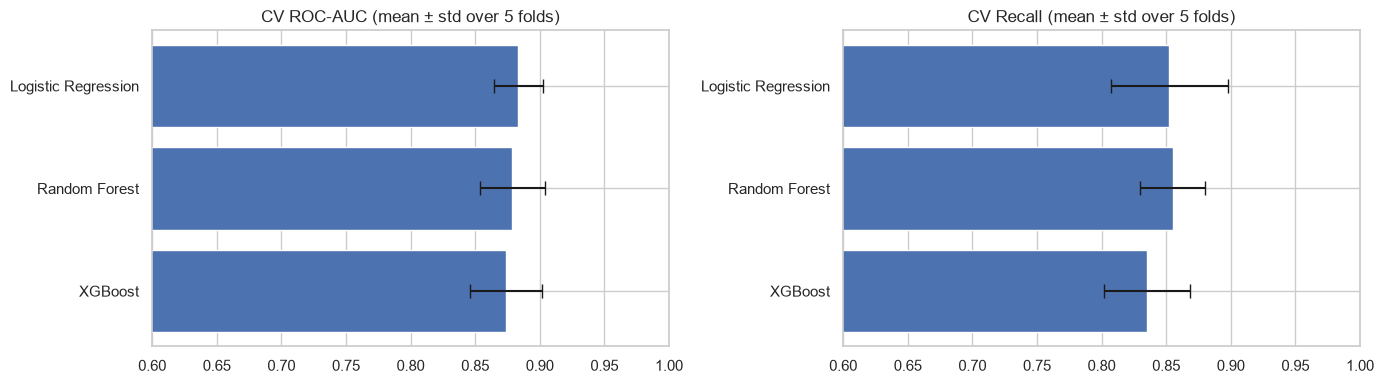

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, m, title in [(axes[0], "roc_auc", "CV ROC-AUC"), (axes[1], "recall", "CV Recall")]:
    ax.barh(results["model"], results[f"cv_{m}"], xerr=results[f"cv_{m}_std"], capsize=5)
    ax.set_xlim(0.6, 1.0)
    ax.set_title(f"{title} (mean ± std over 5 folds)")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

All three models land within roughly one standard deviation of each other, so the differences are mostly **noise between folds** rather than a real gap.
With only ~740 training rows and a handful of features, the simple **Logistic Regression is as good as the tree ensembles** and wins on ROC-AUC — and it is the easiest to explain, which matters in a medical setting.

## 5. What the models learned

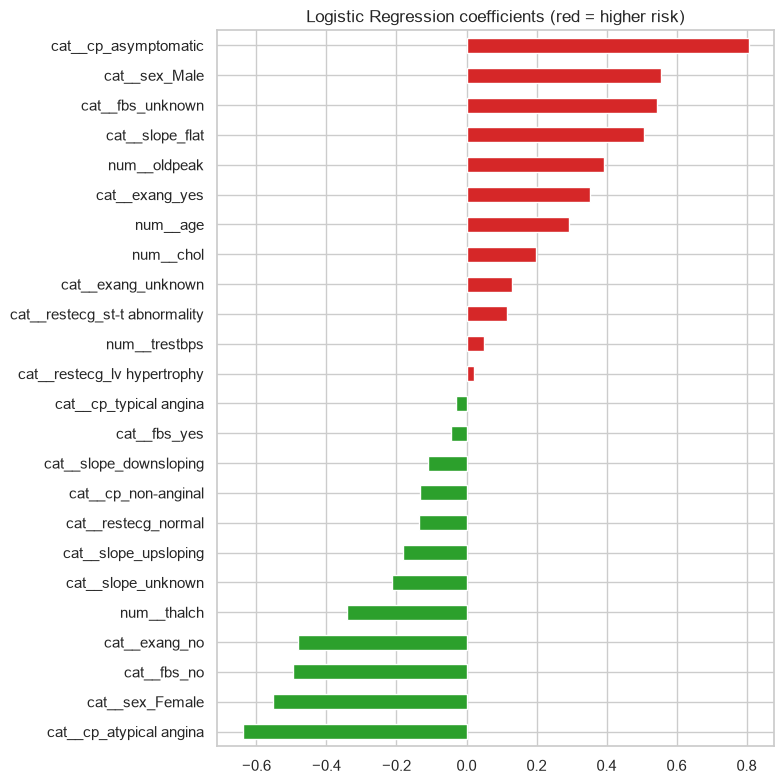

In [7]:
# Logistic Regression coefficients: positive = pushes towards disease
lr = best_models["Logistic Regression"]
names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=names).sort_values()

plt.figure(figsize=(8, 8))
coefs.plot(kind="barh", color=["tab:green" if c < 0 else "tab:red" for c in coefs])
plt.title("Logistic Regression coefficients (red = higher risk)")
plt.tight_layout()
plt.show()

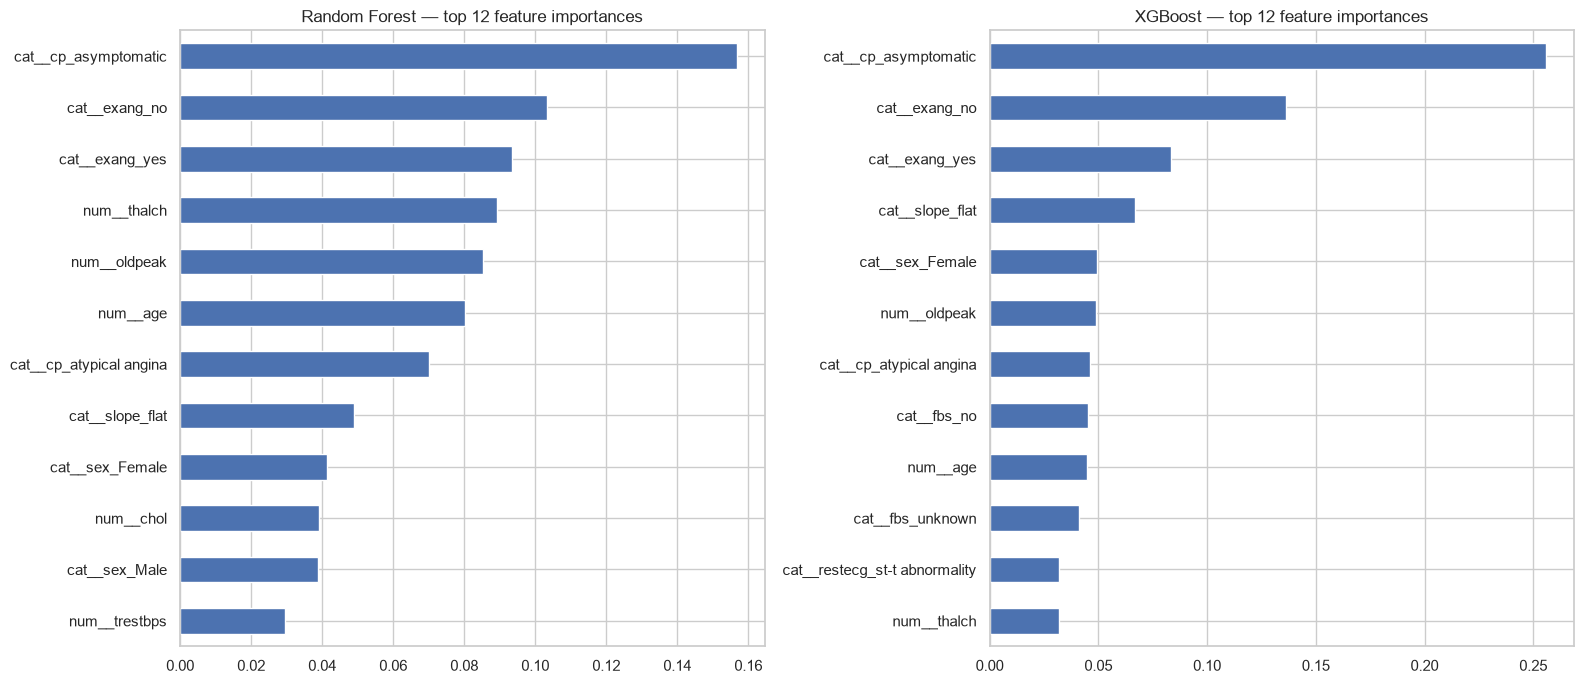

In [8]:
# Tree-model feature importances
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    pipe = best_models[name]
    imp = pd.Series(pipe.named_steps["clf"].feature_importances_,
                    index=pipe.named_steps["prep"].get_feature_names_out()).sort_values()
    imp.tail(12).plot(kind="barh", ax=ax)
    ax.set_title(f"{name} — top 12 feature importances")
plt.tight_layout()
plt.show()

The models agree with the EDA: **asymptomatic chest pain, exercise-induced angina, ST depression (`oldpeak`), max heart rate (`thalch`) and sex** drive the predictions.

## Summary

| | |
|---|---|
| Selection metric | CV ROC-AUC (threshold-independent) |
| Best model | See table above — saved by `python -m src.train` |
| Saved artifacts | `models/heart_model.joblib` (preprocessor + model in one pipeline), `models/model_metadata.json` |

**Next:** evaluate the saved model **once** on the held-out test set, and choose a decision threshold that prioritises recall (missing a sick patient is worse than a false alarm).